In [199]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import svm
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay

In [230]:

# Generate a synthetic 2D dataset with 3 distinct clusters
df=sns.load_dataset('penguins')
df.describe()
df.isna().sum()
df=df.dropna()
df.isna().sum()
df.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='str')

In [218]:
print(df.dtypes)
df=df.drop(columns=['island','sex'],errors='ignore')
le=LabelEncoder()
le.fit_transform(df['species'])
print(df.dtypes)
X=df.drop(columns='species')
y=df['species']

species                  str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
dtype: object
species                  str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
dtype: object


In [219]:

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.5,random_state=42)

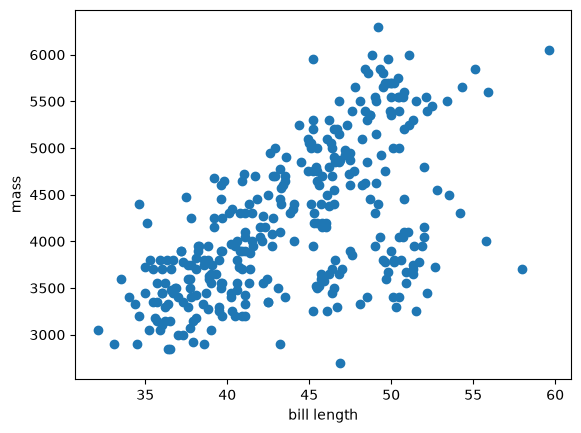

In [220]:

# Plotting the unlabelled data
plt.scatter(df['bill_length_mm'],df['body_mass_g'])
plt.xlabel('bill length')
plt.ylabel('mass')
plt.show()


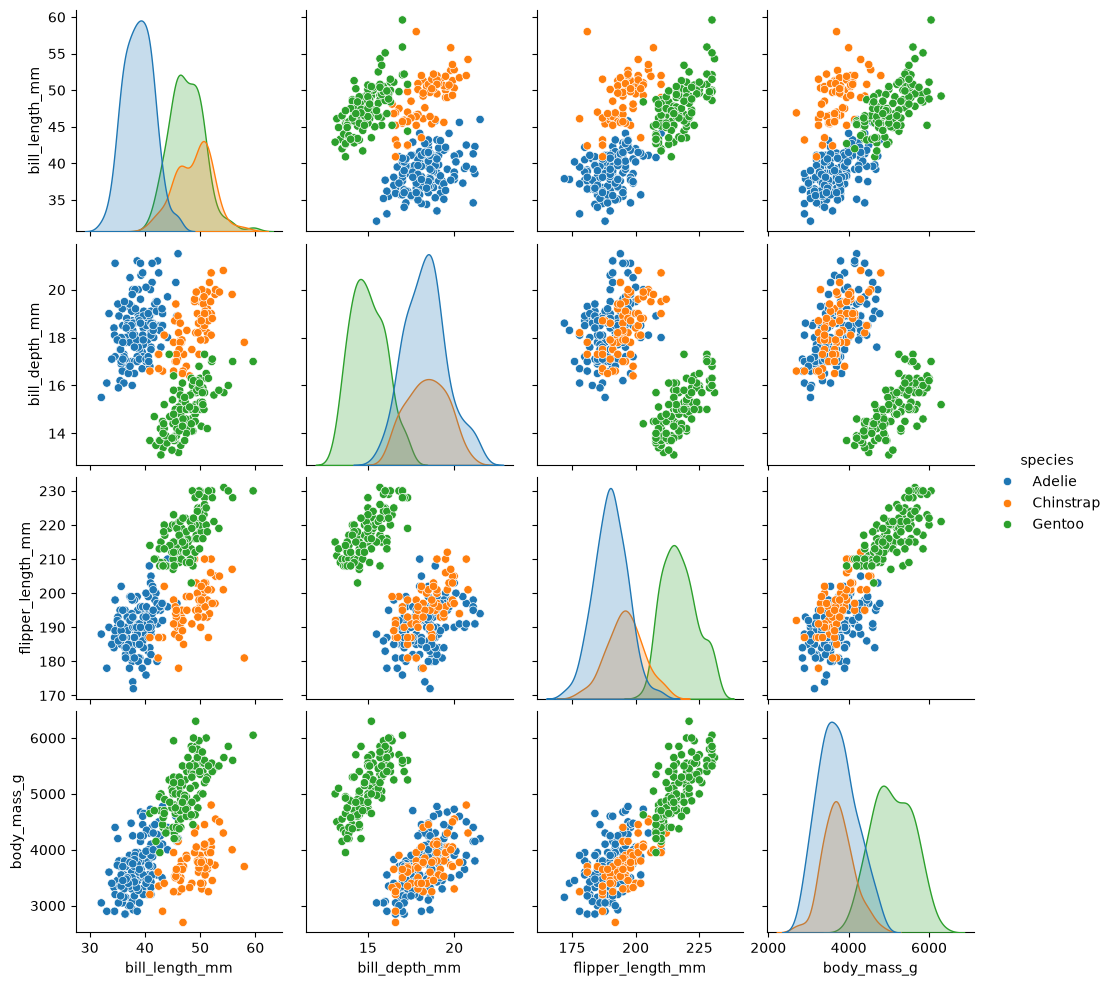

In [221]:
sns.pairplot(data=df,hue='species')

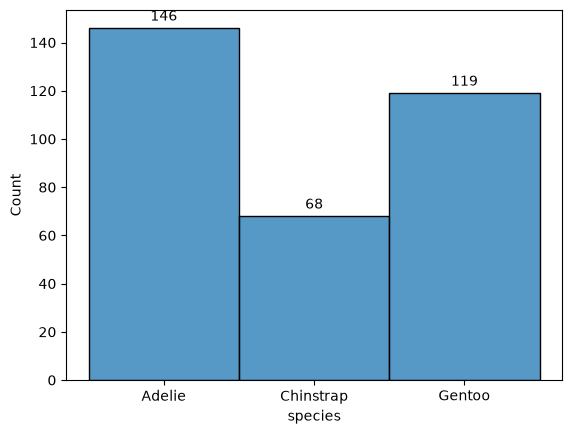

In [222]:
ax=sns.histplot(df['species'])
for cont in ax.containers:
    ax.bar_label(cont, padding=3)
plt.show()

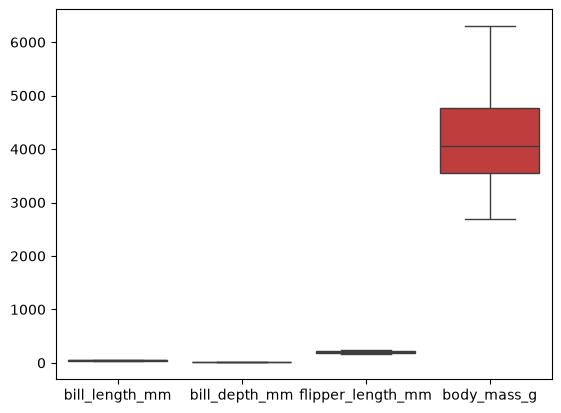

In [223]:
sns.boxplot(X)
plt.show()

In [224]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

clf = svm.SVC()
clf.fit(X_train_scaled, y_train)
y_pred = clf.predict(X_test_scaled)

print(confusion_matrix(y_test, y_pred))
print(accuracy_score(y_test, y_pred))

[[74  1  0]
 [ 1 34  0]
 [ 0  0 57]]
0.9880239520958084


/home/user/miniconda3/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


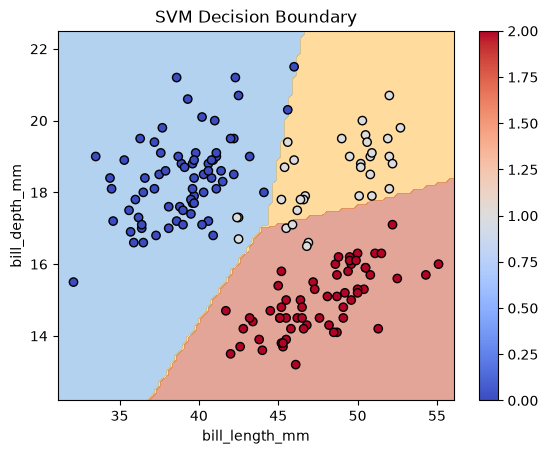

In [233]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
import numpy as np
f1='bill_length_mm'
f2='bill_depth_mm'
X2 = X_train[[f1, f2]]
clf2 = svm.SVC()
clf2.fit(X2, y_train)

fig, ax = plt.subplots()
DecisionBoundaryDisplay.from_estimator(clf2, X2, ax=ax, response_method='predict', cmap='coolwarm', alpha=0.4)
scatter = ax.scatter(X2[f1], X2[f2], c=le.transform(y_train), cmap='coolwarm', edgecolors='k')
ax.set_xlabel(f1)
ax.set_ylabel(f2)
ax.set_title('SVM Decision Boundary')
plt.colorbar(scatter, ax=ax)
plt.show()

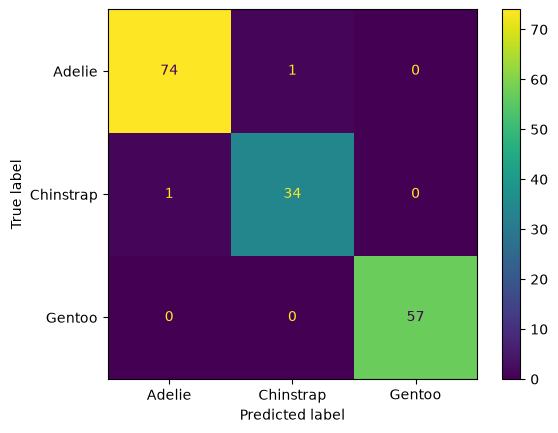

In [228]:
cm=confusion_matrix(y_test,y_pred)
display=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Adelie','Chinstrap','Gentoo'])
display.plot()